In [1]:
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

print("Libraries imported successfully")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Libraries imported successfully


In [2]:
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"

detector = hub.load(MODEL_URL)

print("Model loaded successfully")

Model loaded successfully


In [3]:
COCO_CLASSES = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "motorcycle",
    5: "airplane",
    6: "bus",
    7: "train",
    8: "truck",
    9: "boat",
    10: "traffic light",
    11: "fire hydrant",
    13: "stop sign",
    14: "parking meter",
    15: "bench",
    16: "bird",
    17: "cat",
    18: "dog",
    19: "horse",
    20: "sheep",
    21: "cow",
    22: "elephant",
    23: "bear",
    24: "zebra",
    25: "giraffe",
    27: "backpack",
    28: "umbrella",
    31: "handbag",
    32: "tie",
    33: "suitcase",
    34: "frisbee",
    35: "skis",
    36: "snowboard",
    37: "sports ball",
    38: "kite",
    39: "baseball bat",
    40: "baseball glove",
    41: "skateboard",
    42: "surfboard",
    43: "tennis racket",
    44: "bottle",
    46: "wine glass",
    47: "cup",
    48: "fork",
    49: "knife",
    50: "spoon",
    51: "bowl",
    52: "banana",
    53: "apple",
    54: "sandwich",
    55: "orange",
    56: "broccoli",
    57: "carrot",
    58: "hot dog",
    59: "pizza",
    60: "donut",
    61: "cake",
    62: "chair",
    63: "couch",
    64: "potted plant",
    65: "bed",
    67: "dining table",
    70: "toilet",
    72: "tv",
    73: "laptop",
    74: "mouse",
    75: "remote",
    76: "keyboard",
    77: "cell phone",
    78: "microwave",
    79: "oven",
    80: "toaster",
    81: "sink",
    82: "refrigerator",
    84: "book",
    85: "clock",
    86: "vase",
    87: "scissors",
    88: "teddy bear",
    89: "hair drier",
    90: "toothbrush"
}

print("COCO classes loaded:", len(COCO_CLASSES))

COCO classes loaded: 80


In [4]:
def detect_objects_with_boxes(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Image not found or unreadable: {image_path}")

    orig_image = image.copy()
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    input_tensor = tf.convert_to_tensor(rgb_image, dtype=tf.uint8)
    input_tensor = input_tensor[tf.newaxis, ...]

    detections = detector(input_tensor)

    num_detections = int(detections["num_detections"].numpy()[0])
    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32)
    detection_scores = detections["detection_scores"].numpy()[0]

    height, width, _ = orig_image.shape
    confidence_threshold = 0.5

    for i in range(num_detections):
        score = detection_scores[i]

        if score > confidence_threshold:
            y_min, x_min, y_max, x_max = detection_boxes[i]

            x_min = max(0, min(width - 1, int(x_min * width)))
            x_max = max(0, min(width - 1, int(x_max * width)))
            y_min = max(0, min(height - 1, int(y_min * height)))
            y_max = max(0, min(height - 1, int(y_max * height)))

            class_id = detection_classes[i]
            class_name = COCO_CLASSES.get(class_id, "Unknown")

            label = f"{class_name}: {score:.2f}"

            cv2.rectangle(
                orig_image,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                2
            )

            cv2.putText(
                orig_image,
                label,
                (x_min, max(20, y_min - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    return orig_image

In [7]:
uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Selected image:", image_path)

Saving Screenshot 2026-10-28 120011.png to Screenshot 2026-10-28 120011 (1).png
Selected image: Screenshot 2026-10-28 120011 (1).png


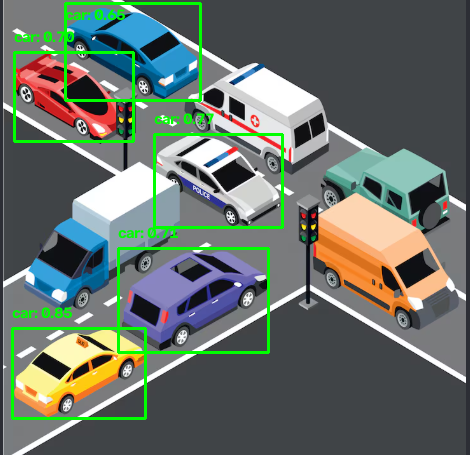

In [8]:
result_image = detect_objects_with_boxes(image_path, detector)

cv2_imshow(result_image)

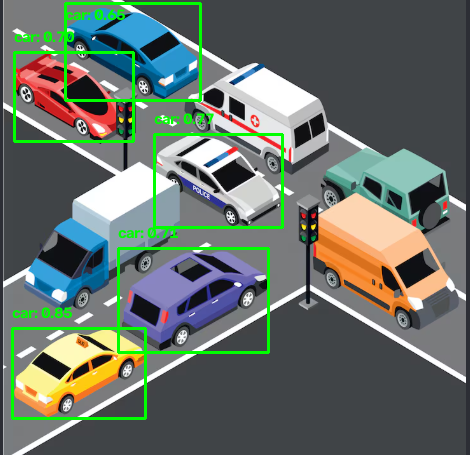

In [9]:
result_image = detect_objects_with_boxes(image_path, detector)
cv2_imshow(result_image)

In [10]:
cv2.imwrite("/content/detected_objects.jpg", result_image)
files.download("/content/detected_objects.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import os

if os.path.exists("/content/detected_objects.jpg"):
    print("Output image saved successfully!")
else:
    print("Run Step 7 first to save the image.")

Output image saved successfully!


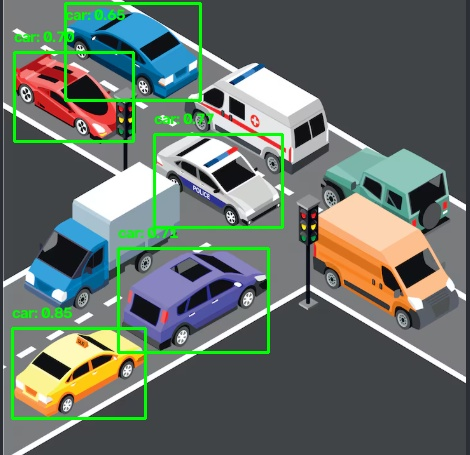

In [12]:
from google.colab.patches import cv2_imshow
cv2_imshow(cv2.imread("/content/detected_objects.jpg"))

In [14]:
image = cv2.imread(image_path)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
input_tensor = tf.convert_to_tensor(rgb_image, dtype=tf.uint8)
input_tensor = input_tensor[tf.newaxis, ...]

detections = detector(input_tensor)

num_detections = int(detections["num_detections"].numpy()[0])
detection_classes = detections["detection_classes"].numpy()[0].astype(int)
detection_scores = detections["detection_scores"].numpy()[0]

count = 0

for i in range(num_detections):
    if detection_scores[i] > 0.5:
        class_id = detection_classes[i]
        class_name = COCO_CLASSES.get(class_id, "Unknown")
        print(class_name, ":", round(float(detection_scores[i]), 2))
        count += 1

print("Total detected objects:", count)

car : 0.85
car : 0.77
car : 0.71
car : 0.7
car : 0.65
Total detected objects: 5


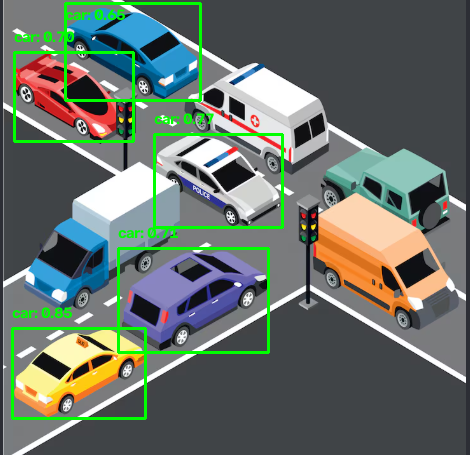

In [15]:
cv2_imshow(result_image)